# Ejercicio 3

## Contexto

Una empresa de logística observa que algunos envíos llegan con retraso. La dirección cree que podrían influir la distancia, el volumen de paquetes y la lluvia, y quiere reducir los tiempos sin disparar el coste.

## Datos disponibles

Genera **60 repartos**, 20 para cada zona (Centro, Norte y Sur).

| Campo | Condición |
|---|---|
| envío | 1 a 60 |
| zona | Centro, Norte, Sur: 20 repartos por zona |
| distancia_km | 5–50km |
| paquetes | 1–5 |
| lluvia | 0 no; 1 sí. Envíos 21–36 con lluvia |
| tiempo_min | 12 + distancia_km * 1.5 + paquetes * 4 + lluvia * 25 + variación |
| coste_eur | 3 + distancia_km * 0.55 + paquetes * 0.80 + lluvia * 2 |

La variación del tiempo estará entre 0 y 12 minutos. Se considera lenta una entrega que supere **90 minutos** y elevado un coste superior a **30€**.

## Lo que tienes que hacer

1. ¿Qué factores parecen relacionarse con la duración de los repartos?
2. ¿Qué zonas presentan más casos problemáticos? ¿Es suficiente la comparación de medias para decidir cuál funciona peor?
3. ¿Cómo se relacionan lluvia, tiempos y costes? Explica los límites de tus conclusiones.
4. ¿Existen repartos costosos que no sean lentos, o lentos que no sean costosos?
5. ¿Qué repartos investigarías primero y qué recomendarías al responsable?

Elige y justifica las gráficas que resulten útiles.

### Entrega

- actividad.py o .ipynb
- repartos.csv
- repartos_problematicos.json
- Gráficos jpg
- Informe de conclusiones

## 1. Generación de datos

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Semilla fija para repetir la simulación.
np.random.seed(42)
envio = np.arange(1, 61)
distancia = np.random.uniform(5, 50, 60)
paquetes = np.random.randint(1, 6, 60)
lluvia = ((envio >= 21) & (envio <= 36)).astype(int)
df = pd.DataFrame({'envío': envio, 'zona': ['Centro'] * 20 + ['Norte'] * 20 + ['Sur'] * 20,
                   'distancia_km': distancia, 'paquetes': paquetes, 'lluvia': lluvia,
                   'tiempo_min': 12 + distancia * 1.5 + paquetes * 4 + lluvia * 25 + np.random.uniform(0, 12, 60),
                   'coste_eur': 3 + distancia * 0.55 + paquetes * 0.80 + lluvia * 2})
df['lento'] = df['tiempo_min'] > 90
df['costoso'] = df['coste_eur'] > 30

print(df.head())
print(df.shape)

   envío    zona  distancia_km  paquetes  ...  tiempo_min  coste_eur  lento  costoso
0      1  Centro     21.854305         5  ...   67.527036  19.019868  False    False
1      2  Centro     47.782144         2  ...   92.596975  30.880179   True     True
2      3  Centro     37.939727         5  ...   92.386609  27.866850   True    False
3      4  Centro     31.939632         2  ...   69.844103  22.166797  False    False
4      5  Centro     12.020839         1  ...   45.187630  10.411461  False    False

[5 rows x 9 columns]
(60, 9)


## 2. Incidencias y exportación

In [ ]:
# Exportamos todos los datos y seleccionamos las incidencias.
df.to_csv('repartos.csv', index=False)
incidencias = df[df['lento'] | df['costoso']]
incidencias.to_json('repartos_problematicos.json', orient='records', indent=4, force_ascii=False)
print(incidencias.to_string(index=False))
print('Total de incidencias:', len(incidencias))
print(pd.crosstab(df['lento'], df['costoso']))


 envío   zona  distancia_km  paquetes  lluvia  tiempo_min  coste_eur  lento  costoso
     2 Centro     47.782144         2       0   92.596975  30.880179   True     True
     3 Centro     37.939727         5       0   92.386609  27.866850   True    False
     8 Centro     43.977927         4       0  104.424417  30.387860   True     True
    12 Centro     48.645943         5       0  111.441022  33.755269   True     True
    21  Norte     32.533380         3       1   97.883496  25.293359   True    False
    25  Norte     25.523149         5       1   96.723108  23.037732   True    False
    26  Norte     40.332918         2       1  109.550759  28.783105   True    False
    29  Norte     31.658656         4       1  106.713471  25.612261   True    False
    31  Norte     32.339518         4       1  105.872833  25.986735   True    False
    34  Norte     47.699849         5       1  131.571161  35.234917   True     True
    35  Norte     48.453441         3       1  127.647144  34.049

## 3. Análisis exploratorio

In [ ]:
print(df.select_dtypes(include='number').corr().round(2))
print(df.groupby('zona').mean(numeric_only=True).round(2))
print(df.groupby('zona')[['lento', 'costoso']].sum())
print(df.groupby('lluvia')[['tiempo_min','coste_eur']].mean())


              envío  distancia_km  paquetes  lluvia  tiempo_min  coste_eur
envío          1.00          0.04      0.13   -0.07        0.02       0.05
distancia_km   0.04          1.00      0.19    0.01        0.87       0.98
paquetes       0.13          0.19      1.00   -0.10        0.33       0.32
lluvia        -0.07          0.01     -0.10    1.00        0.44       0.11
tiempo_min     0.02          0.87      0.33    0.44        1.00       0.93
coste_eur      0.05          0.98      0.32    0.11        0.93       1.00
        envío  distancia_km  paquetes  ...  coste_eur  lento  costoso
zona                                   ...                           
Centro   10.5         25.60       2.9  ...      19.40    0.2     0.15
Norte    30.5         25.47       2.7  ...      20.77    0.4     0.15
Sur      50.5         27.05       3.4  ...      20.60    0.3     0.20

[3 rows x 8 columns]
        lento  costoso
zona                  
Centro      4        3
Norte       8        3
Sur        

## 4. Gráficas

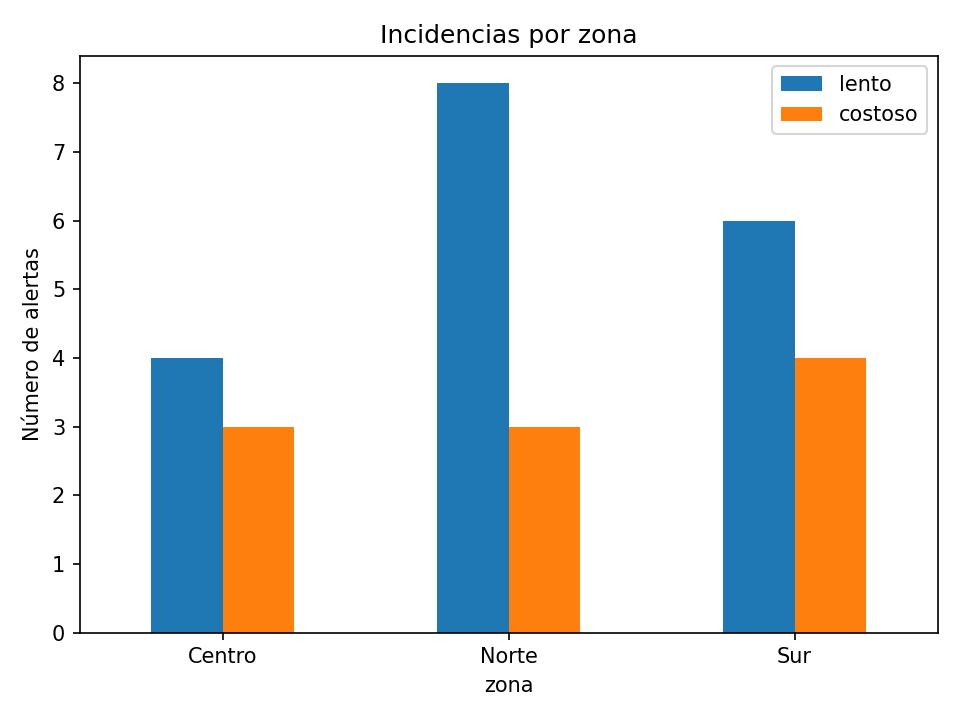

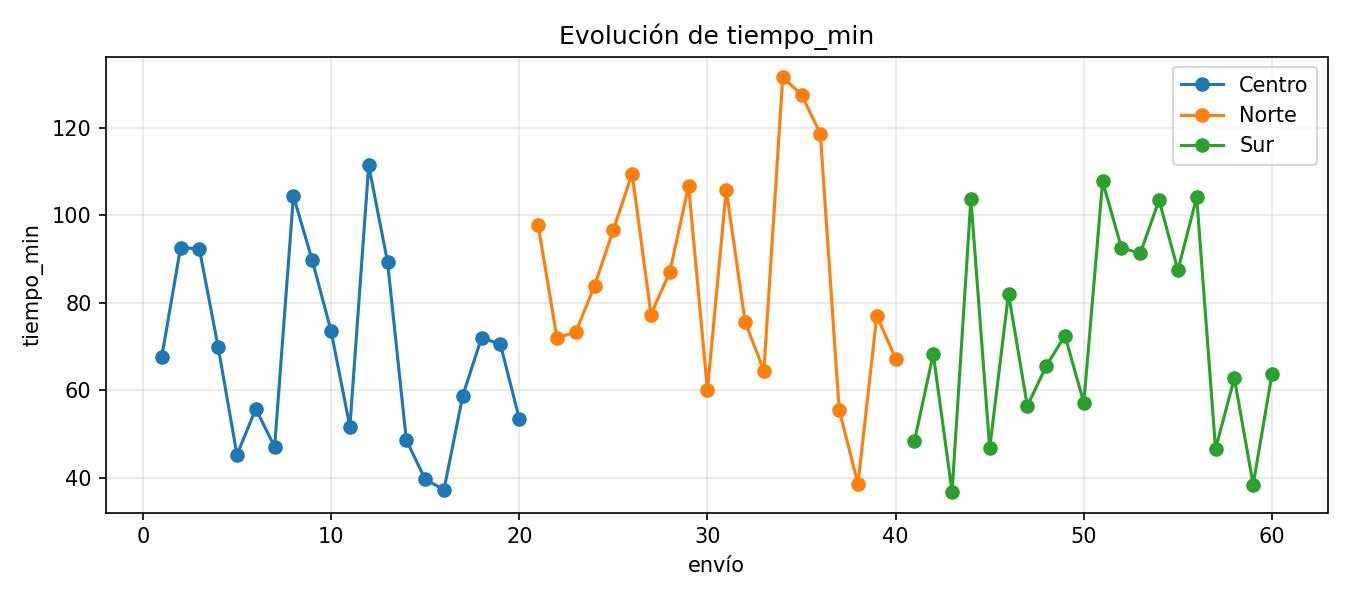

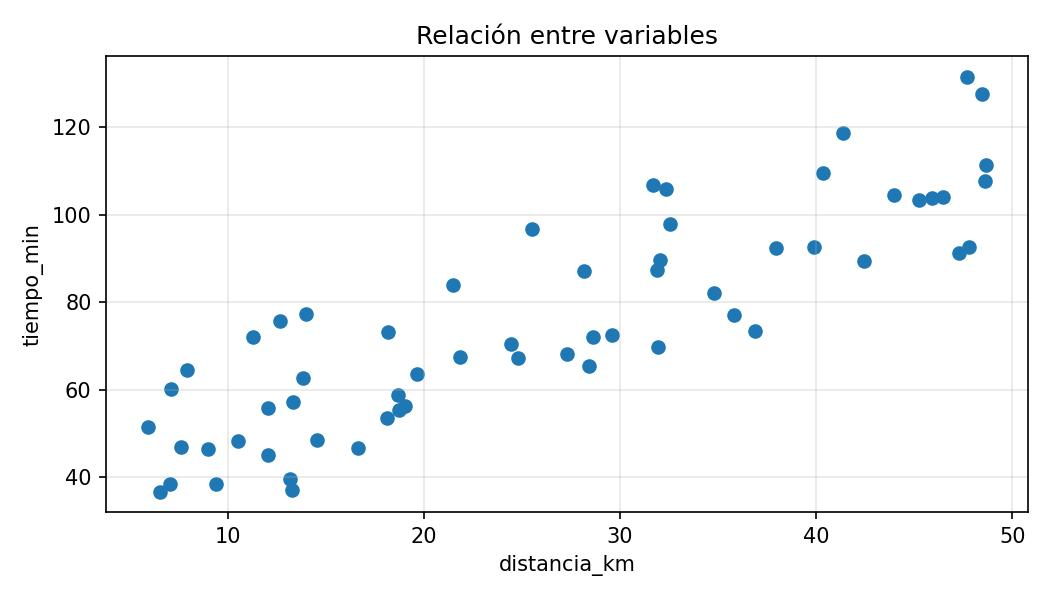

In [ ]:
# Evolución por registro: permite localizar los momentos problemáticos.
plt.figure(figsize=(9, 4))
for nombre, grupo in df.groupby('zona'):
    plt.plot(grupo['envío'], grupo['tiempo_min'], marker='o', label=nombre)
plt.legend()
plt.xlabel('envío'); plt.ylabel('tiempo_min'); plt.title('Evolución de tiempo_min')
plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig('evolucion.jpg', dpi=150); plt.show()
plt.figure(figsize=(7, 4))
plt.scatter(df['distancia_km'], df['tiempo_min'])
plt.xlabel('distancia_km'); plt.ylabel('tiempo_min'); plt.title('Relación entre variables')
plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig('relacion.jpg', dpi=150); plt.show()
df.groupby('zona')[['lento', 'costoso']].sum().plot.bar()
plt.ylabel('Número de alertas'); plt.title('Incidencias por zona'); plt.xticks(rotation=0); plt.tight_layout(); plt.savefig('alertas.jpg', dpi=150); plt.show()


## 5. Conclusiones

1. Correlaciones con tiempo: distancia 0.87, paquetes 0.33, lluvia 0.44.
2. Entregas lentas por zona: {'Centro': 4, 'Norte': 8, 'Sur': 6}. Costosas: {'Centro': 3, 'Norte': 3, 'Sur': 4}. Las medias no reflejan todos los casos extremos.
3. Tiempo medio por lluvia (0/1): {0: 69.19, 1: 93.02}; coste medio: {0: 19.74, 1: 21.66}. La lluvia se concentra en Norte y está incluida en las fórmulas; no es evidencia causal real.
4. Ambos criterios: 10; solo lentos: 8; solo costosos: 0.
5. Priorizar los envíos con ambos criterios, especialmente [34, 35, 36, 12, 51]. Revisar rutas y planificación meteorológica. Las gráficas muestran casos extremos, relación distancia-tiempo y recuentos por zona.

Los datos son simulados y no prueban el comportamiento de un sistema real.